#### Project 2: Classification — "Which metric actually matters, and does my model need calibration?"
- Dataset: Telco Customer Churn (roughly balanced, so you can isolate metric choice from imbalance issues — that's Project 4)  
- The core decision: Logistic Regression vs. SVM vs. k-NN as baselines — but the real exercise is metric selection: 
- If business acts on the probability (e.g., "call customers above 70% churn risk") → you need calibration, not just AUC. A model can have great ROC-AUC and still be miscalibrated.  
- If business just needs a ranked list (top 100 highest-risk customers) → ROC-AUC or just ranking quality matters, calibration doesn't  
- If false positives and false negatives have very different costs → precision/recall/F1, tuned threshold, not accuracy  
- Fundamentals that show up:  
 Cross-validation for model comparison (StratifiedKFold since it's classification)  
- Feature engineering: encoding categoricals, this dataset has a bunch  
- Try k-NN here specifically to feel the curse of dimensionality — one-hot encode everything, watch     
k-NN degrade, then feature-select and watch it recover  
- Deliverable: reliability diagram (calibration curve) for your best model, plus a written call: "for this business use case, I'd deploy with threshold X because..."  

In [1]:
import os
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_style('darkgrid')



In [2]:
df = pd.read_csv('../Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [6]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [7]:
df.loc[df['TotalCharges'].isnull(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [8]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [9]:
df['TotalCharges'].isnull().any()

np.False_

In [10]:
df = df.drop('customerID', axis=1)

In [11]:
df.duplicated().sum()

np.int64(22)

In [12]:
df.nunique()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [13]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [14]:
for i in df.columns:
  x = df[i].value_counts()
  print(x)
  print('_'*24)

gender
Male      3555
Female    3488
Name: count, dtype: int64
________________________
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
________________________
Partner
No     3641
Yes    3402
Name: count, dtype: int64
________________________
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
________________________
tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64
________________________
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
________________________
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
________________________
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
________________________
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int6

Text(0.5, 1.0, 'Gender Distribution')

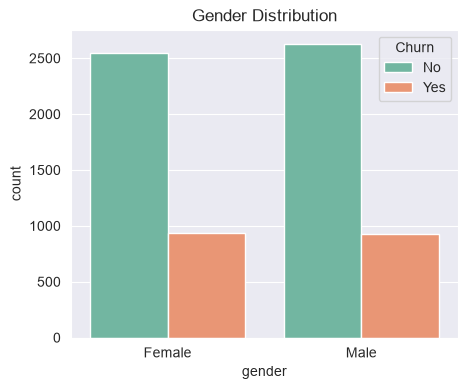

In [15]:
plt.figure(figsize=(5,4))
sns.countplot(x=df['gender'],hue = 'Churn',data = df, palette= 'Set2')
plt.title('Gender Distribution')

Text(0.5, 1.0, 'Senior Citizen vs Churn')

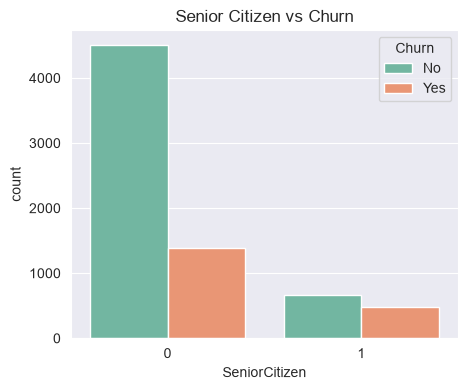

In [16]:
plt.figure(figsize=(5,4))
sns.countplot(x='SeniorCitizen', hue='Churn', data=df, palette='Set2')
plt.title('Senior Citizen vs Churn')

<Axes: xlabel='SeniorCitizen', ylabel='MonthlyCharges'>

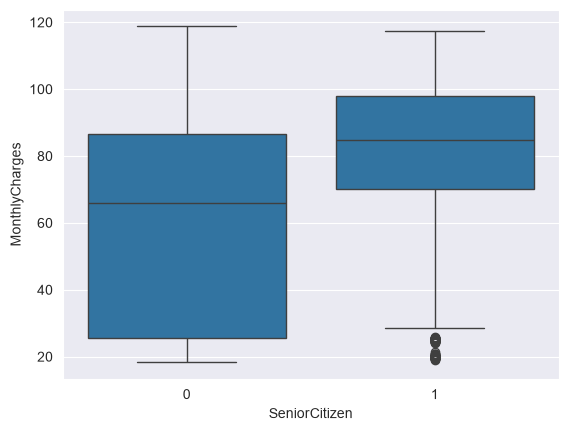

In [17]:
sns.boxplot(x='SeniorCitizen', y='MonthlyCharges', data=df)

Text(0.5, 1.0, 'Partner vs Churn')

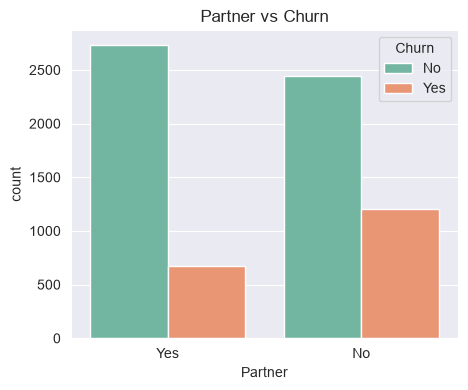

In [18]:
plt.figure(figsize=(5,4))
sns.countplot(x='Partner', hue='Churn', data=df, palette='Set2')
plt.title('Partner vs Churn')

Text(0.5, 1.0, 'Dependents vs Churn')

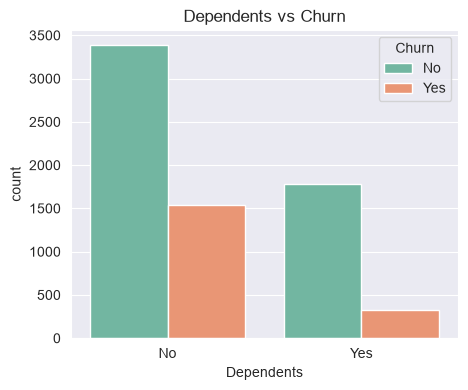

In [19]:
plt.figure(figsize=(5,4))
sns.countplot(x='Dependents', hue='Churn', data=df, palette='Set2')
plt.title('Dependents vs Churn')

Text(0.5, 1.0, 'Phone Service vs Churn')

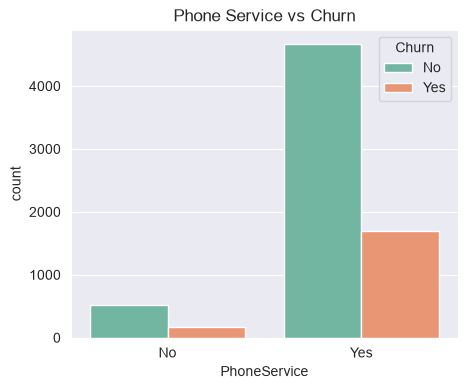

In [20]:
plt.figure(figsize=(5,4))
sns.countplot(x='PhoneService', hue='Churn', data=df, palette='Set2')
plt.title('Phone Service vs Churn')

Text(0.5, 1.0, 'Multiple Lines vs Churn')

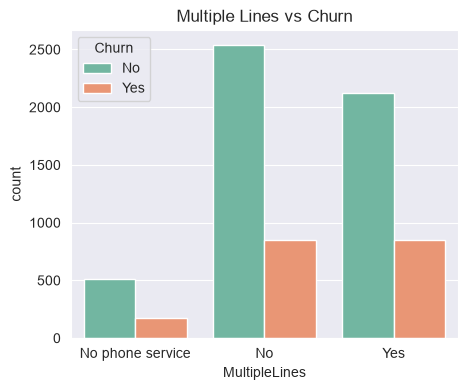

In [21]:
plt.figure(figsize=(5,4))
sns.countplot(x='MultipleLines', hue='Churn', data=df, palette='Set2')
plt.title('Multiple Lines vs Churn')

Text(0.5, 1.0, 'Internet Services vs Churn')

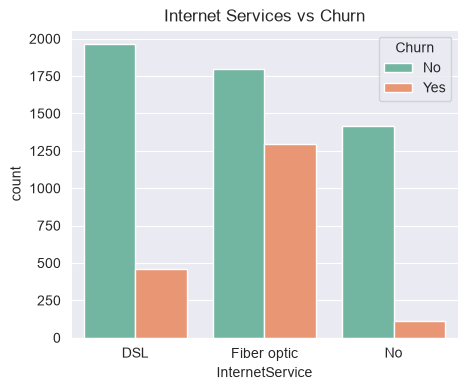

In [22]:
plt.figure(figsize=(5,4))
sns.countplot(x='InternetService', hue='Churn', data=df, palette='Set2')
plt.title('Internet Services vs Churn')

Text(0.5, 1.0, 'Online Security vs Churn')

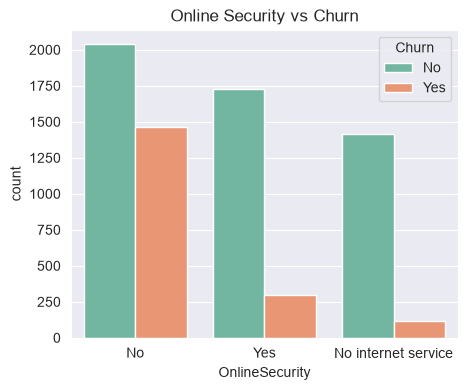

In [23]:
plt.figure(figsize=(5,4))
sns.countplot(x='OnlineSecurity', hue='Churn', data=df, palette='Set2')
plt.title('Online Security vs Churn')

Text(0.5, 1.0, 'Online Backups vs Churn')

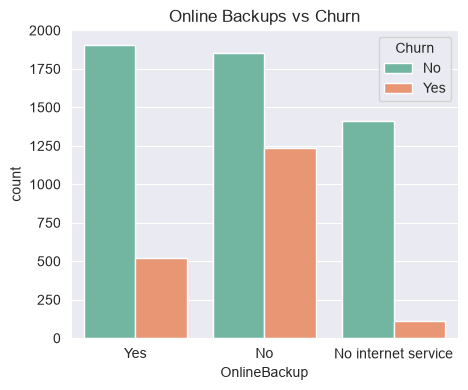

In [24]:
plt.figure(figsize=(5,4))
sns.countplot(x='OnlineBackup', hue='Churn', data=df, palette='Set2')
plt.title('Online Backups vs Churn')

Text(0.5, 1.0, 'Device Protection vs Churn')

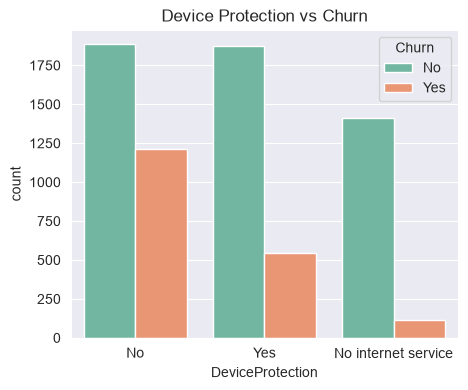

In [25]:
plt.figure(figsize=(5,4))
sns.countplot(x='DeviceProtection', hue='Churn', data=df, palette='Set2')
plt.title('Device Protection vs Churn')

Text(0.5, 1.0, 'Tech Support vs Churn')

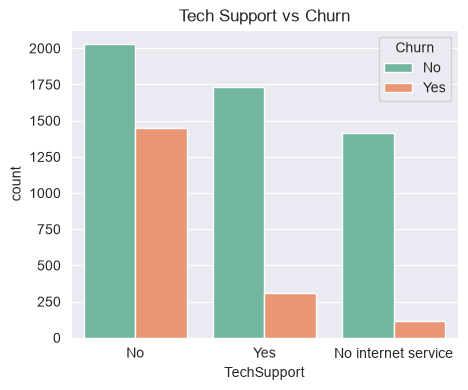

In [26]:
plt.figure(figsize=(5,4))
sns.countplot(x='TechSupport', hue='Churn', data=df, palette='Set2')
plt.title('Tech Support vs Churn')

Text(0.5, 1.0, 'StreamingTV vs Churn')

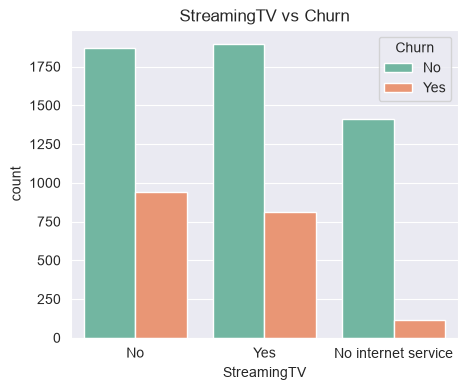

In [27]:
plt.figure(figsize=(5,4))
sns.countplot(x='StreamingTV', hue='Churn', data=df, palette='Set2')
plt.title('StreamingTV vs Churn')

Text(0.5, 1.0, 'StreamingMovies vs Churn')

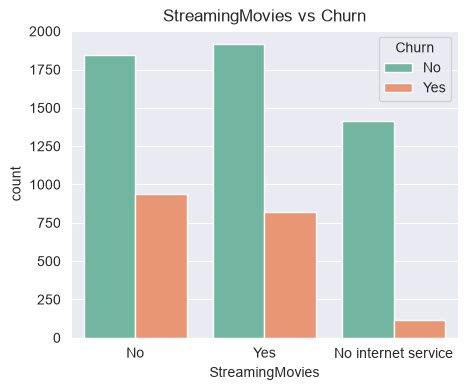

In [28]:
plt.figure(figsize=(5,4))
sns.countplot(x='StreamingMovies', hue='Churn', data=df, palette='Set2')
plt.title('StreamingMovies vs Churn')

Text(0.5, 1.0, 'Contract vs Churn')

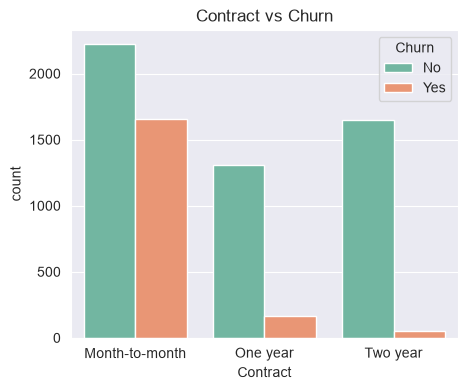

In [29]:
plt.figure(figsize=(5,4))
sns.countplot(x='Contract', hue='Churn', data=df, palette='Set2')
plt.title('Contract vs Churn')

Text(0.5, 1.0, 'PaperlessBilling vs Churn')

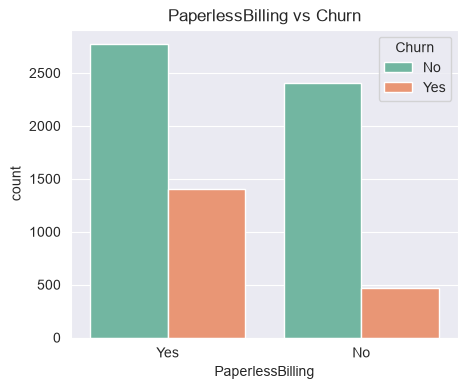

In [30]:
plt.figure(figsize=(5,4))
sns.countplot(x='PaperlessBilling', hue='Churn', data=df, palette='Set2')
plt.title('PaperlessBilling vs Churn')

Text(0.5, 1.0, 'Payment Method vs Churn')

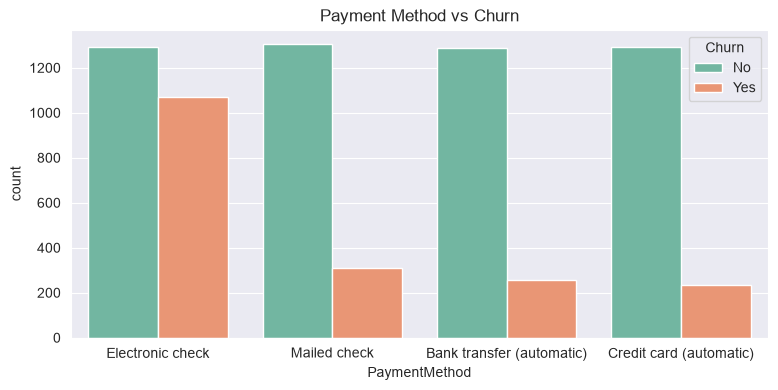

In [31]:
plt.figure(figsize=(9,4))
sns.countplot(x='PaymentMethod', hue='Churn', data=df, palette='Set2')
plt.title('Payment Method vs Churn')

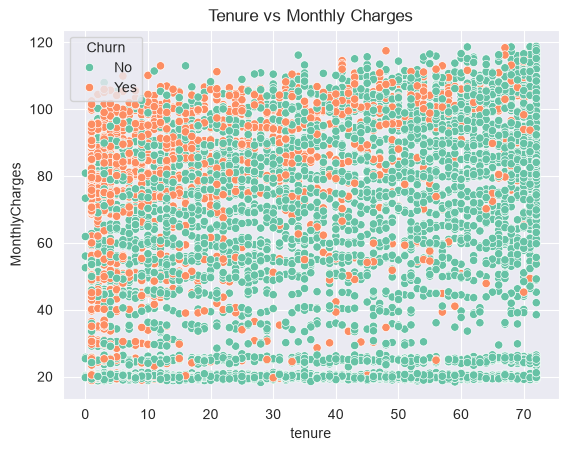

In [32]:
sns.scatterplot(x='tenure', y='MonthlyCharges', hue='Churn', data=df, palette='Set2')
plt.title('Tenure vs Monthly Charges')
plt.show()

In [33]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [34]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

<Axes: xlabel='Churn', ylabel='count'>

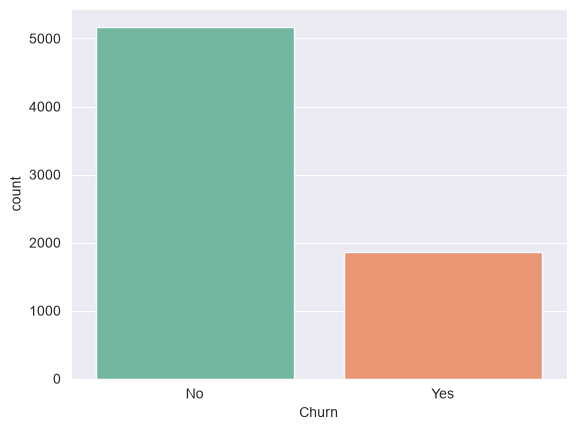

In [35]:
sns.countplot(x=df['Churn'], palette='Set2')

In [36]:
df['Churn'] = df['Churn'].map({'Yes':1, 'No':0})

Text(0.5, 1.0, 'Correlation Map')

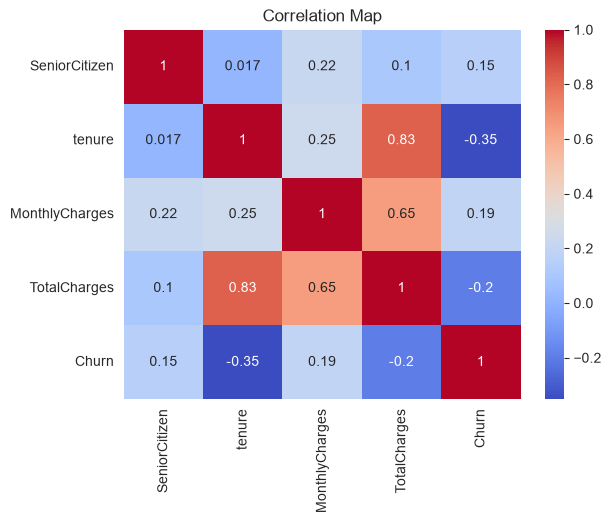

In [37]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Map')

In [38]:
corr['Churn'].sort_values(ascending = False)

Churn             1.000000
MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.198324
tenure           -0.352229
Name: Churn, dtype: float64

In [39]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [40]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2, stratify=y, random_state=42
)

In [41]:
print('X_train', X_train.shape)
print('X_test', X_test.shape)
print('y_train', y_train.shape)
print('X_test', X_test.shape)

X_train (5634, 19)
X_test (1409, 19)
y_train (5634,)
X_test (1409, 19)


In [42]:
cat_cols = X_train.select_dtypes(include=['object']).columns
num_cols = X_train.select_dtypes(exclude=['object']).columns

In [43]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [44]:
encoder = OneHotEncoder(
  handle_unknown='ignore',
  sparse_output=False
)
X_train_encoded = encoder.fit_transform(X_train[cat_cols])
X_test_encoded = encoder.transform(X_test[cat_cols])

In [45]:
encoded_cols = encoder.get_feature_names_out(cat_cols)
X_train_encoded = pd.DataFrame(X_train_encoded, columns=encoded_cols, index=X_train.index)
X_test_encoded = pd.DataFrame(X_test_encoded, columns=encoded_cols, index=X_test.index)

In [46]:
print('X_train_encoded shape:', X_train_encoded.shape)
print('X_test_encoded shape:', X_test_encoded.shape)

X_train_encoded shape: (5634, 41)
X_test_encoded shape: (1409, 41)


In [47]:
X_train_num = X_train.drop(columns=cat_cols)
X_test_num = X_test.drop(columns=cat_cols)

In [48]:
X_train_final = pd.concat([X_train_num, X_train_encoded], axis=1)
X_test_final = pd.concat([X_test_num, X_test_encoded], axis=1)

In [49]:
print('X_train_final shape:', X_train_final.shape)
print('X_test_final shape:', X_test_final.shape)

X_train_final shape: (5634, 45)
X_test_final shape: (1409, 45)


In [50]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

In [51]:
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (5634, 45)
X_test_scaled shape: (1409, 45)


#### Logistic Regression

In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

In [53]:
log_model = LogisticRegression(
  max_iter=1000,
  random_state=42
)
log_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [54]:
y_pred_log = log_model.predict(X_test_scaled)

In [55]:
print('Accuracy: ', accuracy_score(y_test, y_pred_log))
print('Confusion Matrix: \n', confusion_matrix(y_test, y_pred_log))
print('Classification report\n',classification_report(y_test, y_pred_log))

Accuracy:  0.8069552874378992
Confusion Matrix: 
 [[925 110]
 [162 212]]
Classification report
               precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [56]:
y_prob_log = log_model.predict_proba(X_test_scaled)[:,1]
fpr, tpr, threshold = roc_curve(y_test, y_prob_log)
roc_score = roc_auc_score(y_test, y_prob_log)
roc_score

0.8417990648169675

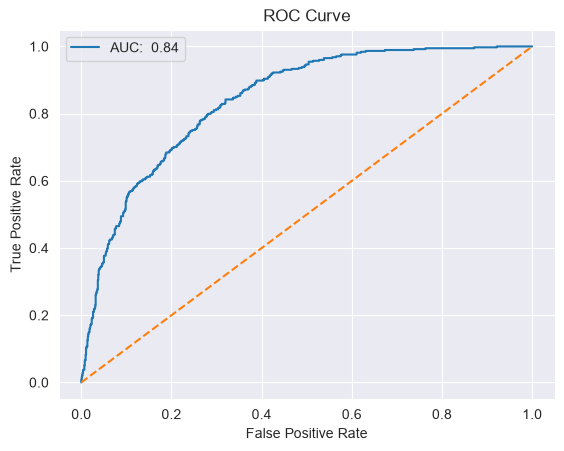

In [57]:
plt.plot(fpr, tpr, label=f'AUC: {roc_score: .2f}')
plt.plot([0,1],[0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [58]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob_log,
    n_bins=10
)

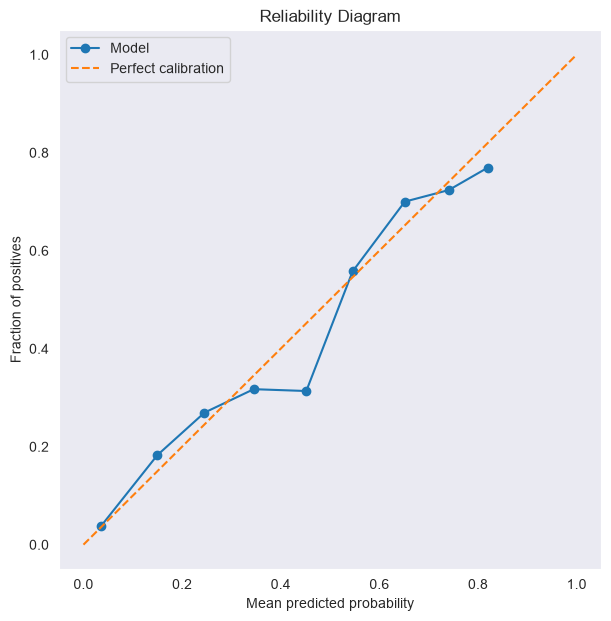

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Reliability Diagram")
plt.legend()
plt.grid()
plt.show()

#### SVM

In [60]:
from sklearn.svm import SVC

In [61]:
svc_model = SVC(
  kernel="rbf",
  class_weight="balanced",
  probability=True,
  random_state=42
  )
svc_model.fit(X_train_scaled,y_train)

,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [62]:
y_pred_svc = svc_model.predict(X_test_scaled)

In [63]:
print('Accuracy: ', accuracy_score(y_test, y_pred_svc))
print('Confusion Matrix: \n', confusion_matrix(y_test, y_pred_svc))
print('Classification report\n',classification_report(y_test, y_pred_svc))

Accuracy:  0.751596877217885
Confusion Matrix: 
 [[771 264]
 [ 86 288]]
Classification report
               precision    recall  f1-score   support

           0       0.90      0.74      0.82      1035
           1       0.52      0.77      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [64]:
y_prob_svc = svc_model.predict_proba(X_test_scaled)[:,1]
fpr, tpr, threshold = roc_curve(y_test, y_prob_svc)
roc_score = roc_auc_score(y_test, y_prob_svc)
roc_score

0.8167725851869074

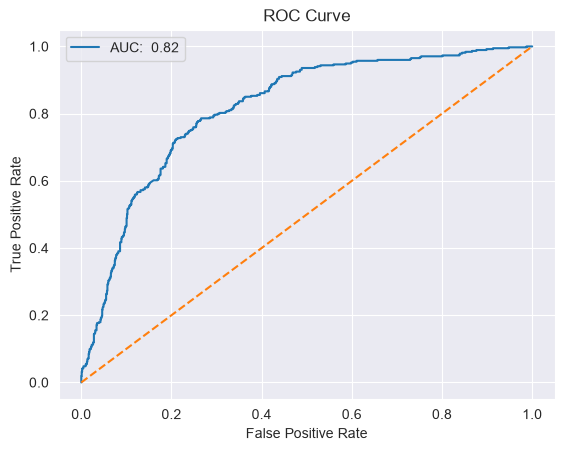

In [65]:
plt.plot(fpr, tpr, label=f'AUC: {roc_score: .2f}')
plt.plot([0,1],[0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [66]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob_svc,
    n_bins=10
)

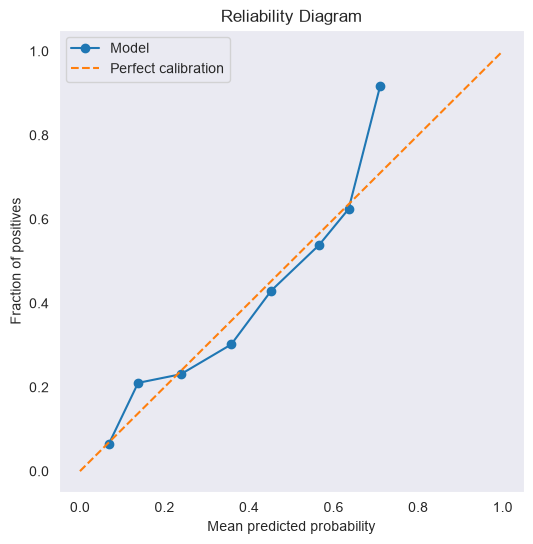

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))

plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Reliability Diagram")
plt.legend()
plt.grid()
plt.show()

In [68]:
from sklearn.neighbors import KNeighborsClassifier

In [69]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)
knn_model.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [70]:
y_pred_knn = knn_model.predict(X_test_scaled)

In [71]:
print('Accuracy: ', accuracy_score(y_test, y_pred_knn))
print('Confusion Matrix: \n', confusion_matrix(y_test, y_pred_knn))
print('Classification report\n',classification_report(y_test, y_pred_knn))

Accuracy:  0.7487579843860894
Confusion Matrix: 
 [[861 174]
 [180 194]]
Classification report
               precision    recall  f1-score   support

           0       0.83      0.83      0.83      1035
           1       0.53      0.52      0.52       374

    accuracy                           0.75      1409
   macro avg       0.68      0.68      0.68      1409
weighted avg       0.75      0.75      0.75      1409



In [72]:
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:,1]
fpr, tpr, threshold = roc_curve(y_test, y_prob_knn)
roc_score = roc_auc_score(y_test, y_prob_knn)
roc_score

0.7700521842465576

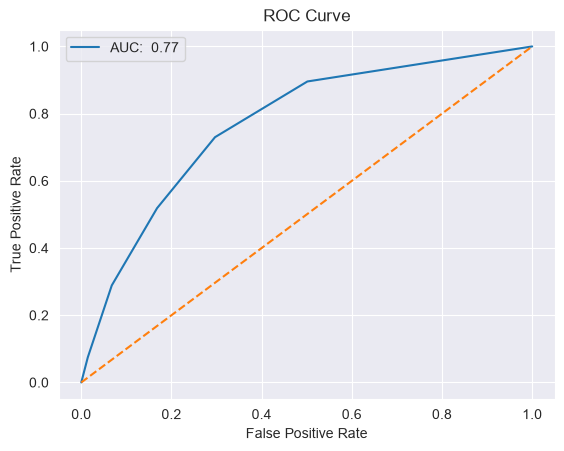

In [73]:
plt.plot(fpr, tpr, label=f'AUC: {roc_score: .2f}')
plt.plot([0,1],[0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [74]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob_knn,
    n_bins=10
)

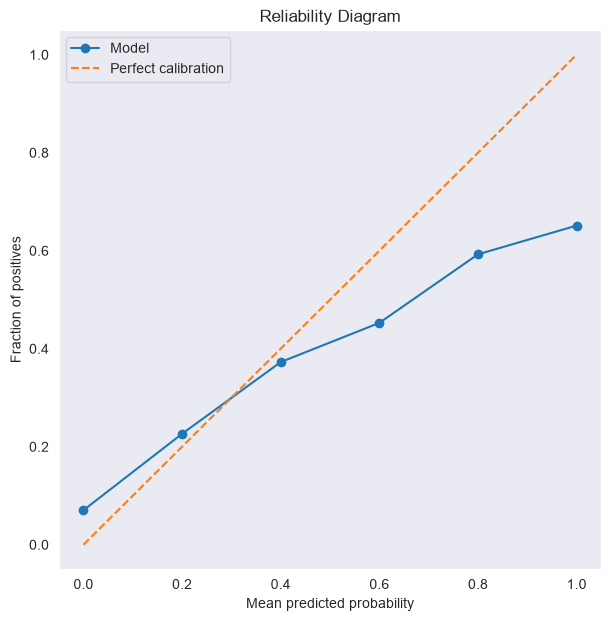

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Reliability Diagram")
plt.legend()
plt.grid()
plt.show()

In [76]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    log_model,
    X_train_scaled,
    y_train,
    cv=skf,
    scoring="roc_auc"
)

print("Fold ROC-AUC scores:", cv_scores)
print("Mean ROC-AUC:", cv_scores.mean())
print("Std ROC-AUC:", cv_scores.std())

Fold ROC-AUC scores: [0.84813711 0.82516399 0.84170666 0.86311255 0.85314612]
Mean ROC-AUC: 0.8462532844499686
Std ROC-AUC: 0.012654839480513715


In [77]:
cv_scores_svm = cross_val_score(
    svc_model,
    X_train_scaled,
    y_train,
    cv=skf,
    scoring="roc_auc"
)

print("Fold ROC-AUC scores:", cv_scores_svm)
print("Mean ROC-AUC:", cv_scores_svm.mean())
print("Std ROC-AUC:", cv_scores_svm.std())

Fold ROC-AUC scores: [0.81722085 0.81510227 0.82529123 0.84067463 0.83487481]
Mean ROC-AUC: 0.8266327594150619
Std ROC-AUC: 0.009883739513876895


In [78]:
cv_scores_knn = cross_val_score(
    knn_model,
    X_train_scaled,
    y_train,
    cv=skf,
    scoring="roc_auc"
)

print("Fold ROC-AUC scores:", cv_scores_knn)
print("Mean ROC-AUC:", cv_scores_knn.mean())
print("Std ROC-AUC:", cv_scores_knn.std())

Fold ROC-AUC scores: [0.76850573 0.77699013 0.77066066 0.76710613 0.78472579]
Mean ROC-AUC: 0.7735976871462708
Std ROC-AUC: 0.006512108086301966


In [79]:
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "k-NN"
    ],
    "Mean ROC-AUC": [
        cv_scores.mean(),
        cv_scores_svm.mean(),
        cv_scores_knn.mean()
    ],
    "Std ROC-AUC": [
        cv_scores.std(),
        cv_scores_svm.std(),
        cv_scores_knn.std()
    ]
})

comparison_df.sort_values(
    "Mean ROC-AUC",
    ascending=False
)

,Model,Mean ROC-AUC,Std ROC-AUC
0,Logistic Regression,0.846253,0.012655
1,SVM,0.826633,0.009884
2,k-NN,0.773598,0.006512


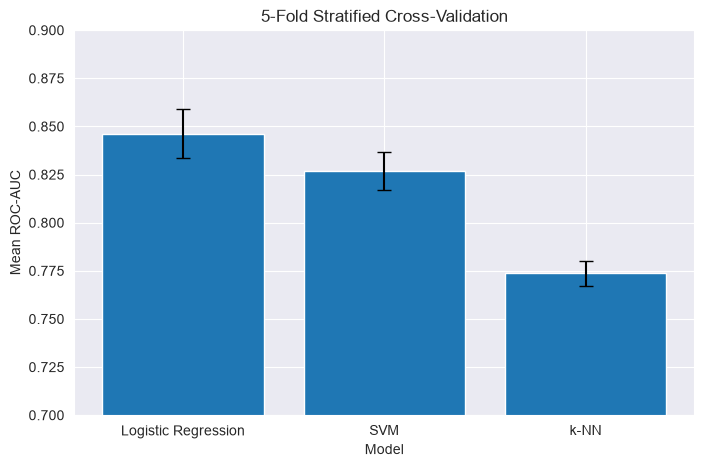

In [80]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Mean ROC-AUC"],
    yerr=comparison_df["Std ROC-AUC"],
    capsize=5
)

plt.ylabel("Mean ROC-AUC")
plt.xlabel("Model")
plt.title("5-Fold Stratified Cross-Validation")
plt.ylim(0.7, 0.9)

plt.show()

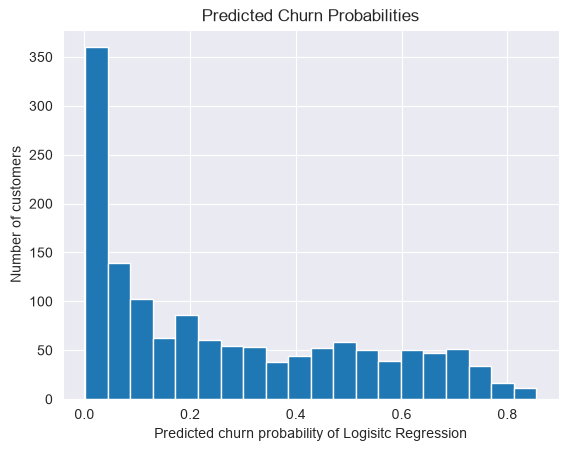

In [81]:
import matplotlib.pyplot as plt

plt.hist(y_prob_log, bins=20)
plt.xlabel("Predicted churn probability of Logisitc Regression")
plt.ylabel("Number of customers")
plt.title("Predicted Churn Probabilities")
plt.show()

In [82]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    y_pred = (y_prob_log >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision_score(y_test, y_pred):.3f} | "
        f"Recall: {recall_score(y_test, y_pred):.3f} | "
        f"F1: {f1_score(y_test, y_pred):.3f}"
    )

Threshold: 0.3 | Precision: 0.518 | Recall: 0.754 | F1: 0.614
Threshold: 0.4 | Precision: 0.566 | Recall: 0.666 | F1: 0.612
Threshold: 0.5 | Precision: 0.658 | Recall: 0.567 | F1: 0.609
Threshold: 0.6 | Precision: 0.713 | Recall: 0.398 | F1: 0.511
Threshold: 0.7 | Precision: 0.730 | Recall: 0.174 | F1: 0.281


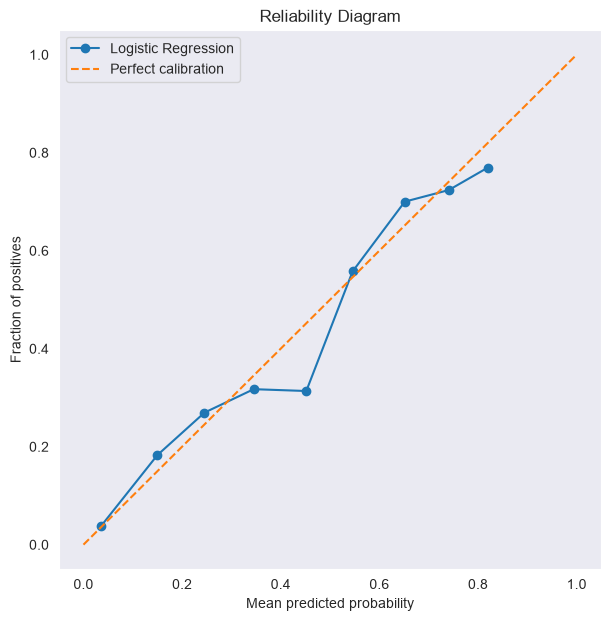

In [83]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob_log,
    n_bins=10
)

plt.figure(figsize=(7, 7))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Reliability Diagram")
plt.legend()
plt.grid()
plt.show()

In [84]:
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(y_test, y_prob_log)
print("Brier Score:", brier)

Brier Score: 0.1382050492012555


In [85]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_lr = CalibratedClassifierCV(
    log_model,
    method="sigmoid",
    cv=5
)

calibrated_lr.fit(X_train_scaled, y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",LogisticRegre...ndom_state=42)
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...002469D97ECF0>, <sk

In [86]:
y_prob_cal = calibrated_lr.predict_proba(X_test_scaled)[:, 1]

In [87]:
brier_cal = brier_score_loss(y_test, y_prob_cal)

print("Original Brier Score:", brier)
print("Calibrated Brier Score:", brier_cal)

Original Brier Score: 0.1382050492012555
Calibrated Brier Score: 0.1381361443748575


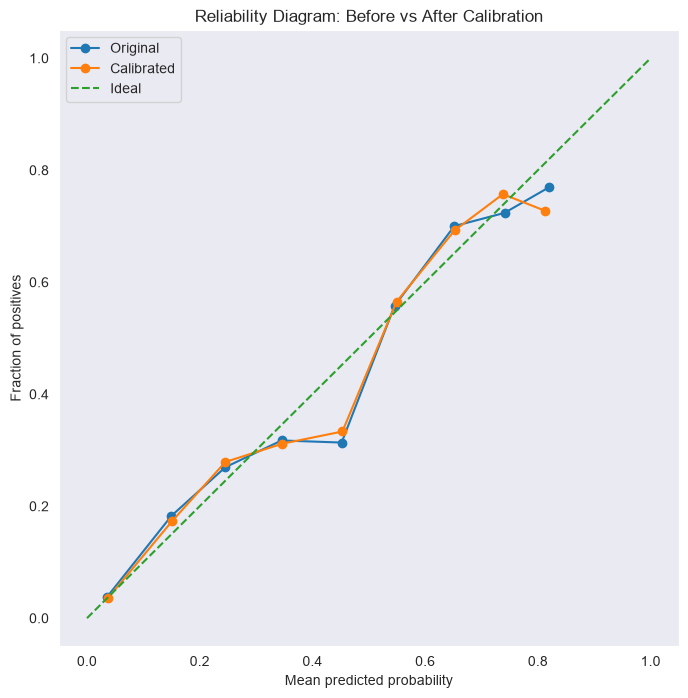

In [88]:
# After calibration
prob_true_cal, prob_pred_cal = calibration_curve(
    y_test,
    y_prob_cal,
    n_bins=10
)

# Plot
plt.figure(figsize=(8, 8))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Original"
)

plt.plot(
    prob_pred_cal,
    prob_true_cal,
    marker="o",
    label="Calibrated"
)

# Perfect calibration line
plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Ideal"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Reliability Diagram: Before vs After Calibration")

plt.legend()
plt.grid()
plt.show()

#### KNN experiment

In [89]:
print("Number of features:", X_train_scaled.shape[1])

Number of features: 45


In [90]:
neighbor_values = [1, 3, 5, 7, 11, 15, 21, 31]

results = []

for n in neighbor_values:

    knn = KNeighborsClassifier(n_neighbors=n)

    scores = cross_val_score(
        knn,
        X_train_scaled,
        y_train,
        cv=skf,
        scoring="roc_auc"
    )

    results.append({
        "n_neighbors": n,
        "Mean ROC-AUC": scores.mean(),
        "Std ROC-AUC": scores.std()
    })

knn_neighbors_df = pd.DataFrame(results)

knn_neighbors_df

,n_neighbors,Mean ROC-AUC,Std ROC-AUC
0,1,0.637314,0.017428
1,3,0.729678,0.011741
2,5,0.773598,0.006512
3,7,0.787809,0.006849
4,11,0.802137,0.003524
5,15,0.814356,0.005582
6,21,0.823778,0.006487
7,31,0.827677,0.008388


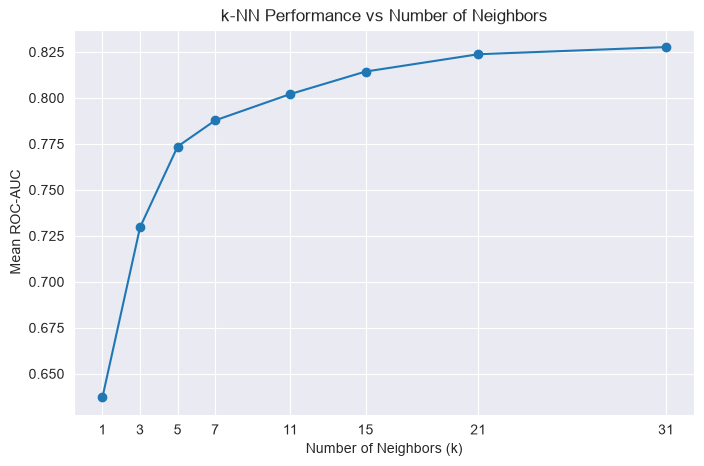

In [91]:
plt.figure(figsize=(8, 5))

plt.plot(
    knn_neighbors_df["n_neighbors"],
    knn_neighbors_df["Mean ROC-AUC"],
    marker="o"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean ROC-AUC")
plt.title("k-NN Performance vs Number of Neighbors")
plt.xticks(neighbor_values)
plt.grid(True)

plt.show()

In [92]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(
    score_func=f_classif,
    k=20
)

X_train_selected = selector.fit_transform(
    X_train_scaled,
    y_train
)

X_test_selected = selector.transform(
    X_test_scaled
)

print("Original features:", X_train_scaled.shape[1])
print("Selected features:", X_train_selected.shape[1])

Original features: 45
Selected features: 20


In [93]:
selected_features = X_train_final.columns[selector.get_support()]

print(selected_features)

Index(['tenure', 'MonthlyCharges', 'TotalCharges',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No', 'OnlineSecurity_No internet service',
       'OnlineBackup_No', 'OnlineBackup_No internet service',
       'DeviceProtection_No', 'DeviceProtection_No internet service',
       'TechSupport_No', 'TechSupport_No internet service',
       'StreamingTV_No internet service',
       'StreamingMovies_No internet service', 'Contract_Month-to-month',
       'Contract_Two year', 'PaperlessBilling_No', 'PaperlessBilling_Yes',
       'PaymentMethod_Electronic check'],
      dtype='str')


In [94]:
feature_scores = pd.DataFrame({
    "Feature": X_train_final.columns,
    "F_score": selector.scores_,
    "Selected": selector.get_support()
})

feature_scores = feature_scores.sort_values(
    "F_score",
    ascending=False
)

feature_scores

,Feature,F_score,Selected
36,Contract_Month-to-month,1114.220194,True
18,OnlineSecurity_No,767.858645,True
1,tenure,763.890183,True
27,TechSupport_No,731.768357,True
16,InternetService_Fiber optic,610.199922,True
43,PaymentMethod_Electronic check,595.424491,True
38,Contract_Two year,566.070664,True
21,OnlineBackup_No,440.506349,True
24,DeviceProtection_No,371.446887,True
34,StreamingMovies_No internet service,311.490238,True


In [95]:
knn_selected = KNeighborsClassifier(n_neighbors=5)

cv_scores_knn_selected = cross_val_score(
    knn_selected,
    X_train_selected,
    y_train,
    cv=skf,
    scoring="roc_auc"
)

print("Fold ROC-AUC scores:", cv_scores_knn_selected)
print("Mean ROC-AUC:", cv_scores_knn_selected.mean())
print("Std ROC-AUC:", cv_scores_knn_selected.std())

Fold ROC-AUC scores: [0.77932682 0.76806747 0.78009226 0.79780831 0.80271198]
Mean ROC-AUC: 0.785601369203875
Std ROC-AUC: 0.012797972000097324


In [96]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

feature_counts = [5, 10, 15, 20, 25, 30, 35, 40, 45]

results = []

for k in feature_counts:

    knn_pipeline = Pipeline([
        ("selector", SelectKBest(score_func=f_classif, k=k)),
        ("knn", KNeighborsClassifier(n_neighbors=5))
    ])

    scores = cross_val_score(
        knn_pipeline,
        X_train_scaled,
        y_train,
        cv=skf,
        scoring="roc_auc"
    )

    results.append({
        "Features": k,
        "Mean ROC-AUC": scores.mean(),
        "Std ROC-AUC": scores.std()
    })

knn_dimensionality_df = pd.DataFrame(results)

knn_dimensionality_df

,Features,Mean ROC-AUC,Std ROC-AUC
0,5,0.763633,0.016767
1,10,0.786928,0.008680
2,15,0.786928,0.008680
3,20,0.785601,0.012798
4,25,0.781649,0.015288
5,30,0.769841,0.015690
6,35,0.773617,0.013743
7,40,0.769564,0.016199
8,45,0.773598,0.006512


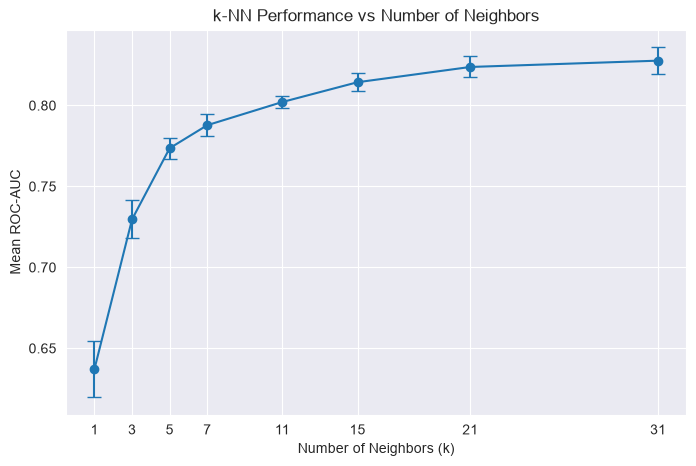

In [97]:
plt.figure(figsize=(8, 5))

plt.errorbar(
    knn_neighbors_df["n_neighbors"],
    knn_neighbors_df["Mean ROC-AUC"],
    yerr=knn_neighbors_df["Std ROC-AUC"],
    marker="o",
    capsize=5
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean ROC-AUC")
plt.title("k-NN Performance vs Number of Neighbors")
plt.xticks(neighbor_values)
plt.grid(True)

plt.show()

In [98]:
best_knn_idx = knn_dimensionality_df["Mean ROC-AUC"].idxmax()

comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "k-NN (45 features)",
        f"k-NN ({knn_dimensionality_df.loc[best_knn_idx, 'Features']} features)"
    ],
    "Mean ROC-AUC": [
        cv_scores.mean(),
        cv_scores_svm.mean(),
        cv_scores_knn.mean(),
        knn_dimensionality_df.loc[best_knn_idx, "Mean ROC-AUC"]
    ],
    "Std ROC-AUC": [
        cv_scores.std(),
        cv_scores_svm.std(),
        cv_scores_knn.std(),
        knn_dimensionality_df.loc[best_knn_idx, "Std ROC-AUC"]
    ]
})

comparison_df = comparison_df.sort_values(
    "Mean ROC-AUC",
    ascending=False
)

comparison_df

,Model,Mean ROC-AUC,Std ROC-AUC
0,Logistic Regression,0.846253,0.012655
1,SVM,0.826633,0.009884
3,k-NN (10 features),0.786928,0.008680
2,k-NN (45 features),0.773598,0.006512
